# Building Energy Efficiency
## 1. Problem definition

Architects comparing early building designs need estimates of heating and cooling load before committing to detailed simulation. The model takes eight design attributes and returns two continuous load estimates, making this a **supervised regression** task.

The test asks how well the model predicts variants of **unseen geometries** within the dataset's simulation setting. Model selection uses mean validation RMSE across the two targets. The final model succeeds if it lowers held-out RMSE for **both** targets compared with predicting a constant mean. We also report MSE and R² for each target. RMSE is in the same units as the recorded load, MSE weights large errors quadratically, and R² measures fit relative to variation in the evaluated target.

## 2. Data collection

Read the supplied workbook and give its short column codes descriptive names. Each of the 768 rows represents an Ecotect simulation. The 12 residential geometries vary in orientation and glazing, which makes these data relevant for early design comparisons inside the simulation domain.

| Source | Meaning |
|---|---|
| X1–X5 | Relative compactness, surface area, wall area, roof area, and overall height |
| X6 | Orientation category (codes 2–5) |
| X7 | Glazing area fraction |
| X8 | Glazing distribution category (codes 0–5, with 0 for no glazing) |
| Y1–Y2 | Heating load and cooling load |

Data source and license are documented by [Tsanas and Xifara, UCI Energy Efficiency](https://archive.ics.uci.edu/dataset/242/energy%2Befficiency).

In VS Code, use **Select Kernel** to choose the project's `.venv/bin/python` (Python 3.15). It may appear as **Building Energy (Python 3.15)** if the kernel is registered. The terminal's active environment is independent of the notebook kernel.

In [25]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.features import CATEGORICAL, FEATURES, NUMERIC, TARGETS, add_roof_fraction

ROOT = Path.cwd()
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
SOURCE_COLUMNS = NUMERIC[:5] + ["orientation", "glazing_area",
                                "glazing_area_distribution"] + TARGETS
raw = pd.read_excel(ROOT / "ENB2012_data.xlsx", usecols="A:J")
raw = raw.rename(columns=dict(zip(
    [f"X{i}" for i in range(1, 9)] + ["Y1", "Y2"], SOURCE_COLUMNS
)))

display(raw.head())
print(f"{len(raw)} simulations, {len(FEATURES)} inputs, {len(TARGETS)} targets")

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


768 simulations, 8 inputs, 2 targets


## 3. Data exploration and preparation

Audit the dataset before splitting. Remove exact duplicates and rows without the targets or geometry needed to assign a split. Normalize invalid category codes to missing values for later imputation. Check physical and glazing consistency. Fail on conflicting values so they can be corrected at the source.

The supplied workbook had no missing values, exact duplicates, or invalid category codes. The checks document those decisions and apply them on reruns.

In [26]:
display(pd.DataFrame({"dtype": raw.dtypes, "missing": raw.isna().sum()}))
print(f"Exact duplicate rows: {raw.duplicated().sum()}")
GEOMETRY = NUMERIC[:5]
data = raw.drop_duplicates().dropna(subset=GEOMETRY + TARGETS).copy()
for column, codes in zip(CATEGORICAL, [range(2, 6), range(6)]):
    invalid_codes = data[column].notna() & ~data[column].isin(codes)
    print(f"Invalid {column} codes set to missing: {invalid_codes.sum()}")
    data.loc[invalid_codes, column] = np.nan

known_glazing = data[["glazing_area", "glazing_area_distribution"]].notna().all(axis=1)
invalid_glazing = (
    data["glazing_area"].notna() & ~data["glazing_area"].between(0, 1)
) | (
    known_glazing & ((data["glazing_area"] == 0) != (data["glazing_area_distribution"] == 0))
)
invalid_geometry = (
    data[GEOMETRY].le(0).any(axis=1)
    | data["relative_compactness"].gt(1)
    | data[["wall_area", "roof_area"]].max(axis=1).gt(data["surface_area"])
)
if (invalid_glazing | invalid_geometry | data[TARGETS].lt(0).any(axis=1)).any():
    raise ValueError("Review invalid building inputs or loads in the source workbook.")
print(f"Rows available after cleaning: {len(data)}")

,dtype,missing
relative_compactness,float64,0
surface_area,float64,0
wall_area,float64,0
roof_area,float64,0
overall_height,float64,0
orientation,int64,0
glazing_area,float64,0
glazing_area_distribution,int64,0
heating_load,float64,0
cooling_load,float64,0


Exact duplicate rows: 0
Invalid orientation codes set to missing: 0
Invalid glazing_area_distribution codes set to missing: 0
Rows available after cleaning: 768


Split by the combination of the five geometry inputs before plotting or fitting. Variants of a geometry stay together, so the held-out scores measure transfer across shapes. Use fixed seeds so the split is reproducible.

In [27]:
from sklearn.model_selection import GroupShuffleSplit

data = data.reset_index(drop=True)
groups = data.groupby(GEOMETRY).ngroup()
development_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=2, random_state=42).split(data, groups=groups)
)
development = data.iloc[development_idx]
train_pos, val_pos = next(
    GroupShuffleSplit(n_splits=1, test_size=2, random_state=43).split(
        development, groups=groups.loc[development.index]
    )
)
train, validation = development.iloc[train_pos], development.iloc[val_pos]
test = data.iloc[test_idx]
partitions = {"Training": train, "Validation": validation, "Test": test}
group_sets = [set(groups.loc[part.index]) for part in partitions.values()]
assert sum(map(len, group_sets)) == len(set.union(*group_sets)) == groups.nunique()
display(pd.DataFrame([
    {"Split": label, "Rows": len(part), "Geometries": len(ids),
     "Compactness values": sorted(part["relative_compactness"].unique().tolist())}
    for (label, part), ids in zip(partitions.items(), group_sets)
]).set_index("Split"))

,Rows,Geometries,Compactness values
Split,,,
Training,512,8,"[0.62, 0.64, 0.66, 0.71, 0.74, 0.76, 0.79, 0.82]"
Validation,128,2,"[0.69, 0.98]"
Test,128,2,"[0.86, 0.9]"


Summarize training distributions and inspect values outside the 1.5×IQR fences. The fences flag candidates for review. Valid extremes are kept because they can represent genuine simulated designs. Plot both target distributions to see which load ranges dominate training.

,count,mean,std,min,25%,50%,75%,max
relative_compactness,512.0,0.72,0.07,0.62,0.66,0.72,0.77,0.82
surface_area,512.0,707.44,66.53,612.50,655.38,698.25,765.62,808.50
wall_area,512.0,327.69,50.46,245.00,306.25,330.75,349.12,416.50
roof_area,512.0,189.88,40.20,122.50,147.00,220.50,220.50,220.50
overall_height,512.0,4.81,1.70,3.50,3.50,3.50,7.00,7.00
glazing_area,512.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40
heating_load,512.0,20.93,10.63,6.01,12.74,15.36,29.50,43.10
cooling_load,512.0,23.23,9.99,10.90,15.19,18.18,31.87,48.03


,relative_compactness,surface_area,wall_area,roof_area,overall_height,glazing_area,heating_load,cooling_load
Outside IQR fences,0,0,64,0,0,0,0,0


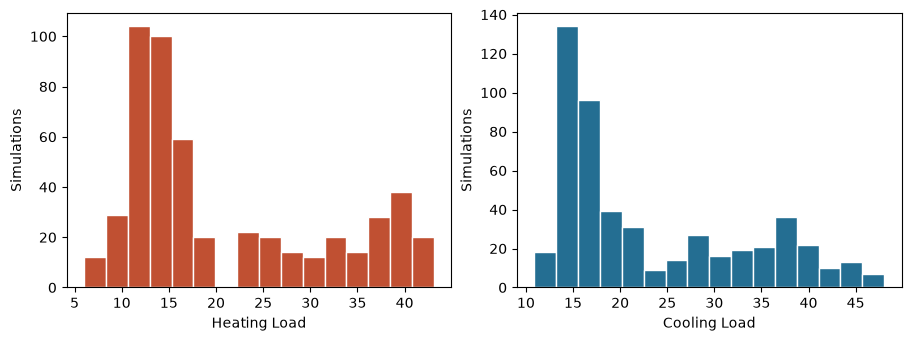

In [28]:
eda = train[NUMERIC + TARGETS]
display(eda.describe().T.round(2))
q1, q3 = eda.quantile(0.25), eda.quantile(0.75)
iqr = q3 - q1
outside = eda.lt(q1 - 1.5 * iqr) | eda.gt(q3 + 1.5 * iqr)
display(outside.sum().rename("Outside IQR fences").to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
for ax, target, color in zip(axes, TARGETS, ["#c05032", "#246e92"]):
    ax.hist(train[target], bins=16, color=color, edgecolor="white")
    ax.set(xlabel=target.replace("_", " ").title(), ylabel="Simulations")
fig.savefig(ARTIFACTS / "target_distributions.png", dpi=150)
plt.show()

Compare numeric correlations and load distributions at each glazing level. Correlations show relationships worth exploring, and glazing box plots reveal how much loads vary within a glazing level. Both reflect the simulation design and the mix of shapes in the training set.

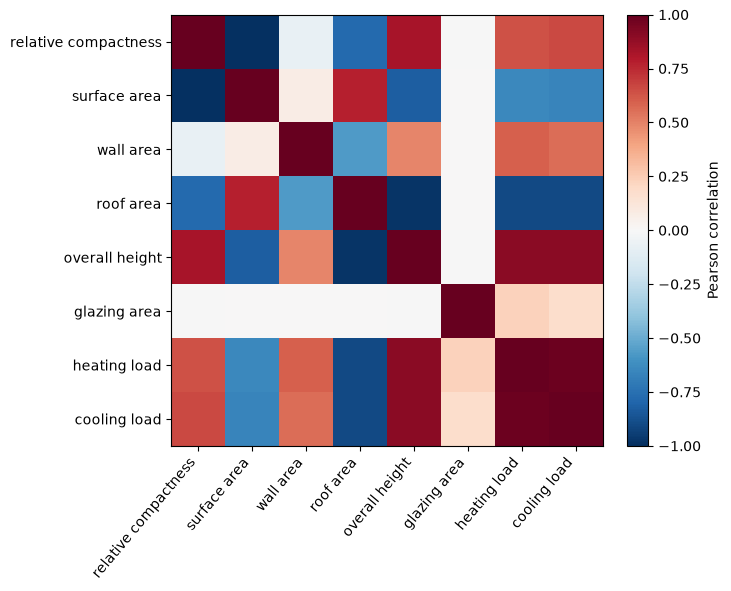

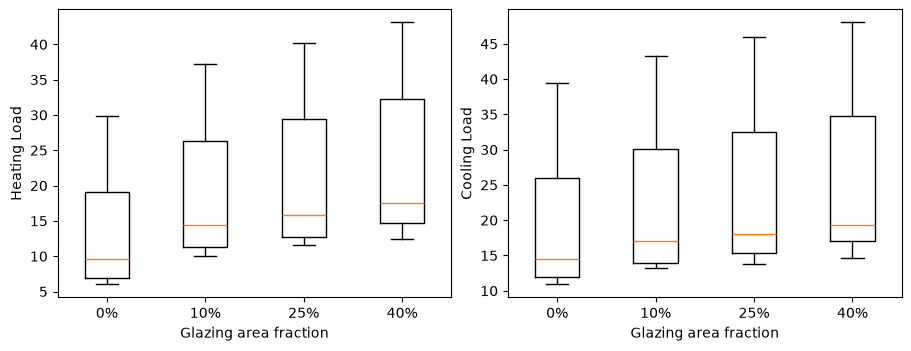

heating_load: strongest numeric correlation is roof_area (r = -0.90). Median load at 0% and 40% glazing is 9.6 and 17.5, respectively.
cooling_load: strongest numeric correlation is overall_height (r = +0.90). Median load at 0% and 40% glazing is 14.5 and 19.3, respectively.


In [29]:
correlations = eda.corr()
fig, ax = plt.subplots(figsize=(7.2, 5.8), layout="constrained")
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [name.replace("_", " ") for name in correlations]
ax.set_xticks(range(len(labels)), labels, rotation=50, ha="right")
ax.set_yticks(range(len(labels)), labels)
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.savefig(ARTIFACTS / "correlations.png", dpi=150)
plt.show()

by_glazing = train.groupby("glazing_area")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
for ax, target in zip(axes, TARGETS):
    ax.boxplot([frame[target] for _, frame in by_glazing],
               tick_labels=[f"{level:.0%}" for level, _ in by_glazing])
    ax.set(xlabel="Glazing area fraction", ylabel=target.replace("_", " ").title())
fig.savefig(ARTIFACTS / "glazing_loads.png", dpi=150)
plt.show()

for target in TARGETS:
    relationships = correlations.loc[NUMERIC, target]
    strongest = relationships.abs().idxmax()
    medians = by_glazing[target].median()
    print(f"{target}: strongest numeric correlation is {strongest} "
          f"(r = {relationships[strongest]:+.2f}). "
          f"Median load at {medians.index[0]:.0%} and {medians.index[-1]:.0%} glazing "
          f"is {medians.iloc[0]:.1f} and {medians.iloc[-1]:.1f}, respectively.")

## 4. Algorithm selection

- **Mean baseline** predicts the average of each training target and provides a minimum performance comparison.
- **Ridge regression** fits an interpretable linear relationship at low computational cost. Its L2 penalty helps stabilize coefficients where size and shape measurements are correlated.
- **Random Forest regression** can capture nonlinear effects and interactions, such as geometry changing the relationship between glazing and load. It costs more to fit, is harder to interpret, and can struggle to extrapolate beyond observed feature ranges.

The task supplies continuous labels, so supervised regression directly addresses it. Clustering and PCA explore or compress inputs, and reinforcement learning requires sequential decisions and rewards. The small tabular dataset supports a focused comparison with Ridge and Random Forest before considering a neural network.

## 5. Model development and training

Build each model as a pipeline. Derive roof fraction from two existing measurements, impute missing numeric and categorical inputs, and one-hot encode the category codes so their numbers carry no implied ordering. Scale Ridge inputs so the penalty acts on comparable numeric scales. Tree splits do not require scaling. Train the baseline and default candidates on the training geometries.

In [30]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

numeric_columns = NUMERIC + ["roof_fraction"]
categories = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)


def regression_pipeline(estimator, scale):
    numeric_steps = [SimpleImputer(strategy="median")]
    if scale:
        numeric_steps.append(StandardScaler())
    preprocess = ColumnTransformer([
        ("numeric", make_pipeline(*numeric_steps), numeric_columns),
        ("categorical", clone(categories), CATEGORICAL),
    ])
    return Pipeline([
        ("features", FunctionTransformer(add_roof_fraction, validate=False)),
        ("preprocess", preprocess),
        ("model", estimator),
    ])


baseline = DummyRegressor(strategy="mean")
candidates = {
    "Ridge": regression_pipeline(Ridge(), scale=True),
    "Random Forest": regression_pipeline(
        RandomForestRegressor(n_estimators=150, random_state=42), scale=False
    ),
}
X_train, y_train = train[FEATURES], train[TARGETS]
baseline.fit(X_train, y_train)
initial_models = {
    name: clone(pipeline).fit(X_train, y_train)
    for name, pipeline in candidates.items()
}
print("Fitted the mean baseline, default Ridge, and default Random Forest.")

Fitted the mean baseline, default Ridge, and default Random Forest.


## 6. Model evaluation and hyperparameter tuning

Use grid search because the candidate grids are small enough to evaluate exhaustively. Scikit-learn's predefined split keeps the validation geometries out of training for every fit. Compare default and tuned candidates with the baseline using the same metrics. The training-to-validation RMSE gap shows how much error increases when predicting unfamiliar geometries.

In [31]:
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, PredefinedSplit


def evaluate(model, frame):
    actual = frame[TARGETS]
    predicted = model.predict(frame[FEATURES])
    return pd.DataFrame({
        "MSE": mean_squared_error(actual, predicted, multioutput="raw_values"),
        "RMSE": root_mean_squared_error(actual, predicted, multioutput="raw_values"),
        "R²": r2_score(actual, predicted, multioutput="raw_values"),
    }, index=pd.Index(TARGETS, name="Target"))


grids = {
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {
        "model__max_depth": [4, 8, None],
        "model__min_samples_leaf": [1, 3, 6],
    },
}
tuning_data = pd.concat([train, validation])
fold = PredefinedSplit([-1] * len(train) + [0] * len(validation))
searches = {}
tuned = {}
for name, pipeline in candidates.items():
    search = GridSearchCV(
        pipeline, grids[name], cv=fold, scoring="neg_root_mean_squared_error",
        refit=False, error_score="raise",
    )
    search.fit(tuning_data[FEATURES], tuning_data[TARGETS])
    searches[name] = search
    tuned[name] = clone(pipeline).set_params(**search.best_params_).fit(X_train, y_train)

selected = max(searches, key=lambda name: (searches[name].best_score_, name == "Ridge"))
models = {"Mean baseline": baseline}
models.update({f"{name} (default)": model for name, model in initial_models.items()})
models.update({f"{name} (tuned)": model for name, model in tuned.items()})
validation_metrics = pd.concat({
    name: pd.concat({"Train": evaluate(model, train), "Validation": evaluate(model, validation)},
                    names=["Split"])
    for name, model in models.items()
}, names=["Model"])
display(validation_metrics.round(3))

grid_results = pd.concat({
    name: pd.DataFrame({
        "Parameters": search.cv_results_["params"],
        "Mean validation RMSE": -search.cv_results_["mean_test_score"],
    }).sort_values("Mean validation RMSE")
    for name, search in searches.items()
}, names=["Model", "Candidate"])
display(grid_results.round(3))
print(f"Selected {selected} with {searches[selected].best_params_}")

MSE    RMSE     R²
Model                   Split      Target                              
Mean baseline           Train      heating_load  112.672  10.615  0.000
                                   cooling_load   99.697   9.985 -0.000
                        Validation heating_load   71.141   8.435 -0.012
                                   cooling_load   57.197   7.563 -0.018
Ridge (default)         Train      heating_load    9.398   3.066  0.917
                                   cooling_load   11.062   3.326  0.889
                        Validation heating_load   85.110   9.226 -0.211
                                   cooling_load  110.969  10.534 -0.975
Random Forest (default) Train      heating_load    0.029   0.169  1.000
                                   cooling_load    0.557   0.747  0.994
                        Validation heating_load    1.188   1.090  0.983
                                   cooling_load    2.201   1.484  0.961
Ridge (tuned)           Train      heating_load   10.998   3.316  0.902
                                   cooling_load   13.025   3.609  0.869
                        Validation heating_load   12.532   3.540  0.822
                                   cooling_load   12.293   3.506  0.781
Random Forest (tuned)   Train      heating_load    0.063   0.252  0.999
                                   cooling_load    1.231   1.109  0.988
                        Validation heating_load    1.136   1.066  0.984
                                   cooling_load    1.868   1.367  0.967

Parameters  \
Model         Candidate                                                      
Ridge         3                                       {'model__alpha': 10}   
              4                                      {'model__alpha': 100}   
              2                                        {'model__alpha': 1}   
              1                                      {'model__alpha': 0.1}   
              0                                     {'model__alpha': 0.01}   
Random Forest 3          {'model__max_depth': 8, 'model__min_samples_le...   
              7          {'model__max_depth': None, 'model__min_samples...   
              4          {'model__max_depth': 8, 'model__min_samples_le...   
              6          {'model__max_depth': None, 'model__min_samples...   
              0          {'model__max_depth': 4, 'model__min_samples_le...   
              1          {'model__max_depth': 4, 'model__min_samples_le...   
              8          {'model__max_depth': None, 'model__min_samples...   
              5          {'model__max_depth': 8, 'model__min_samples_le...   
              2          {'model__max_depth': 4, 'model__min_samples_le...   

                         Mean validation RMSE  
Model         Candidate                        
Ridge         3                         3.523  
              4                         6.606  
              2                         9.880  
              1                        41.221  
              0                        93.128  
Random Forest 3                         1.216  
              7                         1.278  
              4                         1.283  
              6                         1.287  
              0                         1.306  
              1                         1.349  
              8                         1.520  
              5                         1.527  
              2                         1.536

Selected Random Forest with {'model__max_depth': 8, 'model__min_samples_leaf': 1}


Compare the mean RMSE of the two targets on training and validation. An elevated training error suggests a model may be too simple. A low training error with a much larger validation error suggests overfitting or poor transfer to the held-out shapes. With only two validation geometries, the gap alone cannot distinguish those causes.

In [32]:
mean_rmse = validation_metrics["RMSE"].groupby(level=["Model", "Split"]).mean().unstack()
mean_rmse["Gap"] = mean_rmse["Validation"] - mean_rmse["Train"]
display(mean_rmse.sort_values("Validation").round(3))

Split,Train,Validation,Gap
Model,,,
Random Forest (tuned),0.681,1.216,0.536
Random Forest (default),0.458,1.287,0.829
Ridge (tuned),3.463,3.523,0.060
Mean baseline,10.300,7.999,-2.301
Ridge (default),3.196,9.880,6.684


The default forest fit the training data more closely. Limiting its depth lowered validation RMSE from 1.29 to 1.22 and narrowed the train-to-validation gap from 0.83 to 0.54. Tuned Ridge had a smaller gap but higher errors on both splits, consistent with a simpler model missing structure the forest captured.

## 8. Model testing and deployment

Lock in the selected model and refit it on training plus validation. Refit the baseline on the same rows for a fair comparison. Then evaluate both on the two untouched test geometries. Report both targets separately so an improvement on one cannot hide worse performance on the other.

In [33]:
final_model = clone(tuned[selected]).fit(development[FEATURES], development[TARGETS])
final_baseline = clone(baseline).fit(development[FEATURES], development[TARGETS])
model_test = evaluate(final_model, test)
baseline_test = evaluate(final_baseline, test)
test_results = pd.concat({selected: model_test, "Mean baseline": baseline_test}, names=["Model"])
improvement = 100 * (1 - model_test["RMSE"] / baseline_test["RMSE"])
success = bool(improvement.gt(0).all())

display(test_results.round(3))
display(improvement.rename("RMSE reduction vs baseline (%)").round(1).to_frame())
print("Success criterion met." if success else "Success criterion was missed.")

MSE    RMSE     R²
Model         Target                              
Random Forest heating_load   15.728   3.966 -0.001
              cooling_load   21.325   4.618 -0.532
Mean baseline heating_load  102.957  10.147 -5.551
              cooling_load  101.047  10.052 -6.261

,RMSE reduction vs baseline (%)
Target,
heating_load,60.9
cooling_load,54.1


Success criterion met.


Plot observed versus predicted test loads to see the size and direction of errors. The diagonal marks perfect predictions. The colors identify the two held-out geometries so errors concentrated in one shape are visible.

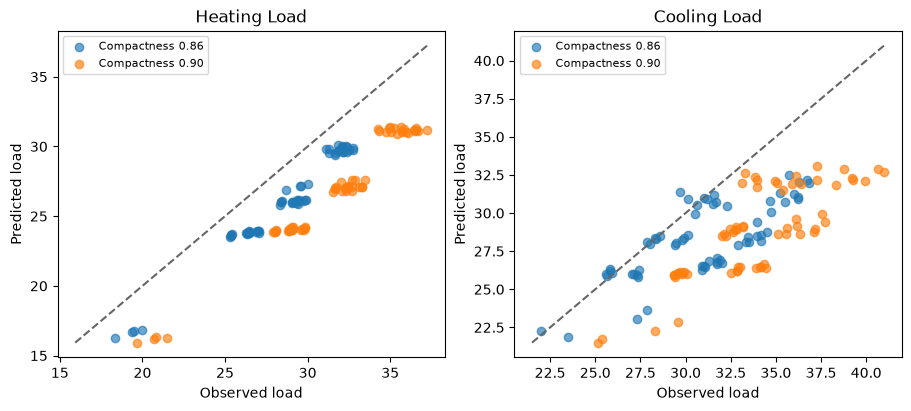

In [34]:
predictions = pd.DataFrame(final_model.predict(test[FEATURES]), index=test.index, columns=TARGETS)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, target in zip(axes, TARGETS):
    for compactness, frame in test.groupby("relative_compactness"):
        ax.scatter(frame[target], predictions.loc[frame.index, target],
                   alpha=0.65, label=f"Compactness {compactness:.2f}")
    low = min(test[target].min(), predictions[target].min())
    high = max(test[target].max(), predictions[target].max())
    ax.plot([low, high], [low, high], "--", color="0.4")
    ax.set(xlabel="Observed load", ylabel="Predicted load", title=target.replace("_", " ").title())
    ax.legend(fontsize=8)
fig.savefig(ARTIFACTS / "test_predictions.png", dpi=150)
plt.show()

Save the fitted pipeline and the feature ranges from its fitting data. Use the training-only geometry for the API example so sample requests are independent of the test report. Exercise the HTTP routes in process on every notebook run and compare the returned estimates against the fitted estimator.

In [35]:
from fastapi.testclient import TestClient

from src.app import app

bounds = {column: (float(development[column].min()), float(development[column].max()))
          for column in FEATURES}
model_file = ARTIFACTS / "model.joblib"
joblib.dump({"pipeline": final_model, "training_bounds": bounds}, model_file, compress=3)

sample = train[FEATURES].iloc[0].to_dict()
sample.update({column: int(sample[column]) for column in CATEGORICAL})
with TestClient(app) as client:
    health = client.get("/health")
    valid = client.post("/predict", json=sample)
    invalid = client.post("/predict", json={**sample, "orientation": 99})
    assert health.status_code == 200 and health.json() == {"status": "ready"}
    assert valid.status_code == 200 and invalid.status_code == 422
    np.testing.assert_allclose(
        [valid.json()[target] for target in TARGETS],
        final_model.predict(train[FEATURES].iloc[[0]])[0],
    )
print(f"Health {health.status_code}; prediction {valid.status_code}; malformed request {invalid.status_code}")
display(sample, valid.json())

Health 200; prediction 200; malformed request 422


{'relative_compactness': 0.82,
 'surface_area': 612.5,
 'wall_area': 318.5,
 'roof_area': 147.0,
 'overall_height': 7.0,
 'glazing_area': 0.0,
 'orientation': 2,
 'glazing_area_distribution': 0}

{'heating_load': 16.992933333333344, 'cooling_load': 23.197933333333314}

### Run the local service

From the project directory, run `python -m uvicorn src.app:app --host 127.0.0.1 --port 8000`. Visit [the interactive API docs](http://127.0.0.1:8000/docs) and use the sample design printed above with `POST /predict`. Clients can send the same JSON over HTTP and receive `heating_load` and `cooling_load`. The service loads the fitted pipeline on startup and exposes `GET /health` for readiness.

The loopback HTTP check returned 200 for readiness and the example prediction, and 422 for an invalid orientation. The prediction matched the notebook. The request with an 8.0 overall height returned 200 and logged the out-of-range field. The observed prediction request took about 14 ms of server time in this local run. See `artifacts/http_verification.json` for the recorded requests.

## 10. Monitoring and maintenance

Uvicorn logs a JSON record for each request with status, response time in milliseconds, and any input fields outside the model's fitting ranges. For a local check, repeat a valid prediction and change `overall_height` to 8.0 on the next request. The out-of-range field should appear in the logs. Track latency, rejected requests, and the frequency of out-of-range inputs across time. These signals show changes in requests and service behavior.

To measure performance after rollout, collect feedback on prediction usefulness and pair agreed design inputs with comparable reference loads when they become available. Recompute RMSE by target and geometry. Investigate sustained error increases or a change in the input mix, then re-validate on newly held-out geometries before replacing the model.

## 11. Documentation and reporting

Summarize the selected model, test RMSE, and improvement over the baseline. Use these numbers and the plots above in the presentation. Save the results as a small JSON file so the slides can be checked against the executed notebook.

In [36]:
import json

report = {
    "model": selected,
    "parameters": searches[selected].best_params_,
    "rows": {label: len(part) for label, part in partitions.items()},
    "test_geometries": sorted(test["relative_compactness"].unique().tolist()),
    "test_metrics": model_test.to_dict(orient="index"),
    "baseline_metrics": baseline_test.to_dict(orient="index"),
    "rmse_reduction_pct": improvement.to_dict(),
    "success": success,
    "sample": sample,
    "sample_prediction": valid.json(),
}
(ARTIFACTS / "results.json").write_text(json.dumps(report, indent=2) + "\n")
print(f"Selected by validation: {selected}.")
for target in TARGETS:
    print(f"{target.replace('_', ' ').title()}: test RMSE {model_test.loc[target, 'RMSE']:.2f} "
          f"vs baseline {baseline_test.loc[target, 'RMSE']:.2f} "
          f"({improvement[target]:+.1f}% reduction).")

Selected by validation: Random Forest.
Heating Load: test RMSE 3.97 vs baseline 10.15 (+60.9% reduction).
Cooling Load: test RMSE 4.62 vs baseline 10.05 (+54.1% reduction).


### Interpretation and reproducibility

The evaluation covers two unseen shapes from a single simulation dataset. Performance may vary across other held-out shapes, building materials, climates, or real operating conditions. Use the estimates for comparisons within the study setting and obtain independent validation before using them in engineering decisions.

Set up the project from this directory with Python 3.15.

```zsh
python3.15 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

With a uv-created environment active, `uv pip install -r requirements.txt` also works. From the project directory, open this notebook in a Python kernel from that environment and choose **Run All**, or run `python -m nbconvert --ExecutePreprocessor.kernel_name=python3 --to notebook --execute --inplace Building_Energy_Efficiency.ipynb`. Keep the workbook and `src` folder beside the notebook. The generated `artifacts` folder contains the model, plots, and summary. The PowerPoint presents the workflow and findings.

The forest met the assignment criterion, reducing test RMSE by 60.9% for heating and 54.1% for cooling against the development-mean baseline. Test R² was −0.001 for heating and −0.532 for cooling. An R² below zero means a constant equal to the respective test target's own mean would have lower squared error. That constant uses the held-out labels, while the deployment baseline uses the development set. Mean test RMSE also rose to 4.29 from 1.22 on validation, indicating the two validation shapes were easier to predict than the two test shapes in this experiment.